# Preset libraries

Ready-made patterns, gradients, filters, markers and effects, each a catalogue you can add to: one sheet
per catalogue, a sentence whose words burn, smoke, shine, blow and snow while staying text, the same
effects on shapes, and gooey blobs.

    python 19_presets.py                writes 19_patterns.svg, 19_gradients.svg, 19_filters.svg,
                                        19_markers.svg, 19_sentence.svg/.gif, 19_shapes.svg and
                                        19_goo.svg/.gif

In [1]:
import svgwriter as svg

Patterns are paints: `fill=svg.patterns.stripes(angle=45, gap=6)` puts a `<pattern>` into `<defs>`.
Without a `color=` they take the theme role `pattern`, so they follow the document theme.

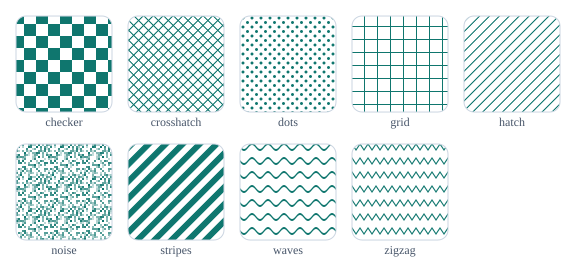

In [2]:
CELL, GAP, LABEL = 96, 16, 16


def sheet(names: list[str], columns: int, background: str = "white") -> tuple[svg.Document, list[tuple[float, float]]]:
    """A document with a labelled cell per name, and the top-left corner of each cell."""
    rows = -(-len(names) // columns)
    width, height = columns * (CELL + GAP) + GAP, rows * (CELL + GAP + LABEL) + GAP
    doc = svg.Document(width, height)
    doc.rect(0, 0, width, height, fill=background)
    corners = []
    for index, name in enumerate(names):
        x = GAP + index % columns * (CELL + GAP)
        y = GAP + index // columns * (CELL + GAP + LABEL)
        doc.text(name, x=x + CELL / 2, y=y + CELL + LABEL - 2, font_size=12, text_anchor="middle", fill="#475569")
        corners.append((x, y))
    return doc, corners


patterns, corners = sheet(svg.patterns.__all__, 5)
for name, (x, y) in zip(svg.patterns.__all__, corners, strict=True):
    patterns.rect(x, y, CELL, CELL, rx=10, fill=getattr(svg.patterns, name)(), stroke="#cbd5e1")
patterns.save("19_patterns.svg")
patterns

Gradients blend in OKLCH, so `blend("red", "blue")` stays vivid through the middle. `theme` runs from the
palette's primary to its accent; `mesh` layers radial blends from four corners.

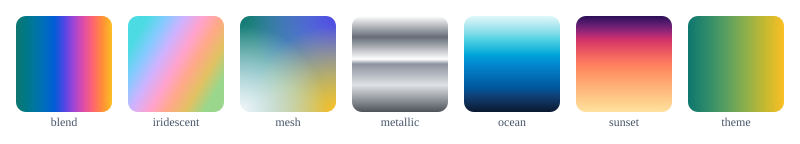

In [3]:
gradients, corners = sheet(svg.gradients.__all__, 7)
for name, (x, y) in zip(svg.gradients.__all__, corners, strict=True):
    gradients.rect(x, y, CELL, CELL, rx=10, fill=getattr(svg.gradients, name)())
gradients.save("19_gradients.svg")
gradients

Filters go straight onto an element: `card.filter = svg.filters.long_shadow()`. Shadows and outlines take
their color from the theme unless you pass one. `goo` melts shapes that come close into one body.

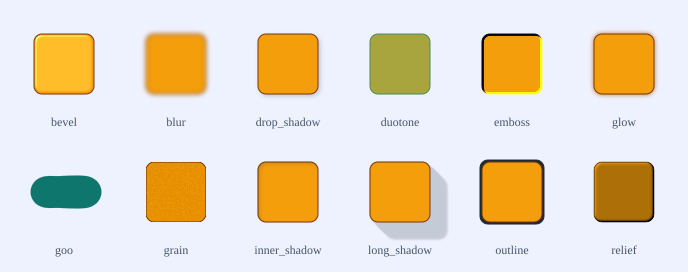

In [4]:
filters, corners = sheet(svg.filters.__all__, 6, background="#eef2ff")
for name, (x, y) in zip(svg.filters.__all__, corners, strict=True):
    if name == "goo":
        with filters.group() as blobs:
            for cx in (x + 30, x + 52, x + 70):
                filters.circle(cx, y + CELL / 2, 15, fill="#0f766e")
        blobs.filter = svg.filters.goo()
        continue
    card = filters.rect(x + 18, y + 18, CELL - 36, CELL - 36, rx=8, fill="#f59e0b", stroke="#78350f")
    card.filter = getattr(svg.filters, name)()
filters.save("19_filters.svg")
filters

Markers are sized in stroke widths and turn with the line, so one marker fits any stroke.

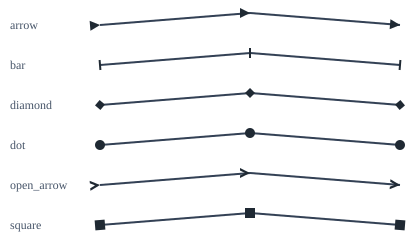

In [5]:
markers = svg.Document(420, 40 * len(svg.markers.__all__) + 10)
for index, name in enumerate(svg.markers.__all__):
    head = getattr(svg.markers, name)()
    y = 25 + index * 40
    markers.text(name, x=10, y=y + 4, font_size=12, fill="#475569")
    markers.path(f"M100 {y} L250 {y - 12} L400 {y}", fill="none", stroke="#334155", stroke_width=2,
                 marker_start=head, marker_mid=head, marker_end=head)
markers.save("19_markers.svg")
markers

Effects style any element, and on a text a whole line or a range of it; the words stay text. `text[a:b].effect("fire")` and
`svg.effects.fire(text[a:b])` move the range onto a copy of the line just above it, so the filter
reaches only those letters. Every effect animates with SMIL, so the SVG plays in a browser and the
same document renders to a GIF or a video.

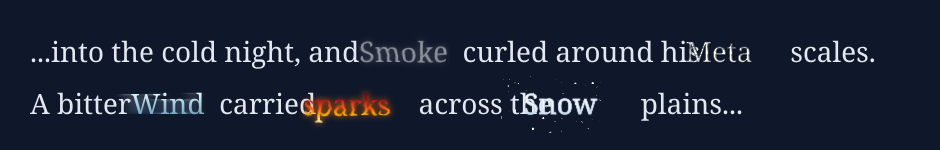

In [6]:
LINES = ("...into the cold night, and Smoke curled around his Metal scales.",
         "A bitter Wind carried sparks across the Snow plains...")
WORDS = {"Smoke": "smoke", "Metal": "metal", "Wind": "wind", "sparks": "fire", "Snow": "snow"}

sentence = svg.Document(940, 150)
sentence.rect(0, 0, 940, 150, fill="#0f172a")
for row, words in enumerate(LINES):
    line = sentence.text(words, x=30, y=62 + row * 52, font_size=28, fill="#e2e8f0", font_family="Georgia, serif")
    for word, effect in WORDS.items():
        if word in words:
            start = words.index(word)
            line[start:start + len(word)].effect(effect)
sentence.save("19_sentence.svg")
sentence.save("19_sentence.gif")
sentence

The same effects on shapes size themselves to the shape's bounding box instead of the glyph height.

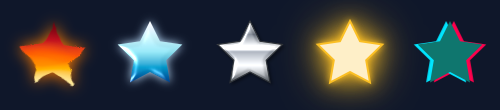

In [7]:
shapes = svg.Document(500, 110)
shapes.rect(0, 0, 500, 110, fill="#0f172a")
for column, effect in enumerate(("fire", "ice", "metal", "neon", "glitch")):
    shapes.add(svg.builder.star(50 + column * 100, 55, 34, points=5)).effect(effect)
shapes.save("19_shapes.svg")
shapes

Gooey blobs: two circles drift apart and back under `svg.filters.goo`, which blurs the group and
sharpens its alpha again, so the circles stretch a bridge before they part.

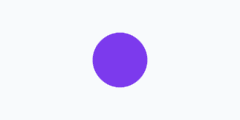

In [8]:
goo = svg.Document(240, 120)
goo.rect(0, 0, 240, 120, fill="#f8fafc")
with goo.group(fill="#7c3aed") as blobs:
    goo.circle(120, 60, 26)
    for shift in (-70, 70):
        drop = goo.circle(120, 60, 18)
        drop.animate.move_by(shift, 0, 1.5).move_by(-shift, 0, 1.5, begin=1.5)
blobs.filter = svg.filters.goo(10)
goo.save("19_goo.svg")
goo.save("19_goo.gif")
goo

Your own presets join the catalogues: `@svg.preset.pattern`, `filter`, `gradient`, `marker` and
`effect` register a function under its name, beside the built-in ones.

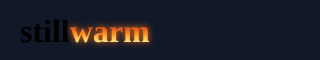

In [9]:
@svg.preset.effect
def ember(element: svg.Element, *, color: str = "#f97316") -> None:
    """Glowing coals: the fire gradient without the flames."""
    element.fill = svg.gradients.blend("#fde68a", color, "#7f1d1d", angle=-90)
    element.filter = svg.filters.glow(3, color=color)


embers = svg.Document(320, 60)
embers.rect(0, 0, 320, 60, fill="#111827")
title = embers.text("still warm", x=20, y=42, font_size=32, font_weight="bold")
title[6:].effect("ember")
embers